# TRƯỜNG ĐẠI HỌC CÔNG NGHIỆP TP. HỒ CHÍ MINH (IUH)
## KHOA CÔNG NGHỆ THÔNG TIN - BỘ MÔN KHOA HỌC DỮ LIỆU & AI
---
### BÁO CÁO BÀI TẬP THỰC HÀNH TUẦN 5: CHƯƠNG 5 - NHẬP MÔN MACHINE LEARNING
- **Học phần:** Phân tích Dữ liệu và Trí tuệ Nhân tạo
- **Giảng viên hướng dẫn:** TS. Ngô Hữu Dũng
- **Sinh viên thực hiện:** Nguyễn Trung Tín
- **Mã số sinh viên (MSSV):** 24654081
---

## 1. THỰC HÀNH 5-1: HỒI QUY TUYẾN TÍNH ĐƠN BIẾN
Xây dựng mô hình Linear Regression từ 1 đặc trưng đầu vào (`total_rooms`) để dự đoán giá nhà trung vị (`median_house_value`).
link: https://www.kaggle.com/datasets/camnugent/california-housing-prices

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Đọc tập dữ liệu California Housing
df_housing = pd.read_csv("dataset/housing.csv")

# Tách biến độc lập X và biến mục tiêu y
X_single = df_housing[["total_rooms"]]
y_target = df_housing["median_house_value"]

# Chia tập huấn luyện và kiểm thử (80% train - 20% test)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_single, y_target, test_size=0.2, random_state=42
)

# Khởi tạo và huấn luyện mô hình
reg_simple = LinearRegression()
reg_simple.fit(X_train_s, y_train_s)

# Dự đoán và tính toán các chỉ số sai số
y_pred_s = reg_simple.predict(X_test_s)
mse_val = mean_squared_error(y_test_s, y_pred_s)
rmse_val = np.sqrt(mse_val)
r2_val = r2_score(y_test_s, y_pred_s)

print(f"Hệ số góc w1: {reg_simple.coef_[0]:.4f} | Hệ số chặn w0: {reg_simple.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mse_val:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_val:.2f} USD")
print(f"Hệ số xác định R² Score: {r2_val:.4f}")

Hệ số góc w1: 7.1240 | Hệ số chặn w0: 188373.09
Mean Squared Error (MSE): 12868608472.63
Root Mean Squared Error (RMSE): 113439.89 USD
Hệ số xác định R² Score: 0.0180


### Trực quan hóa đường hồi quy tuyến tính đơn biến

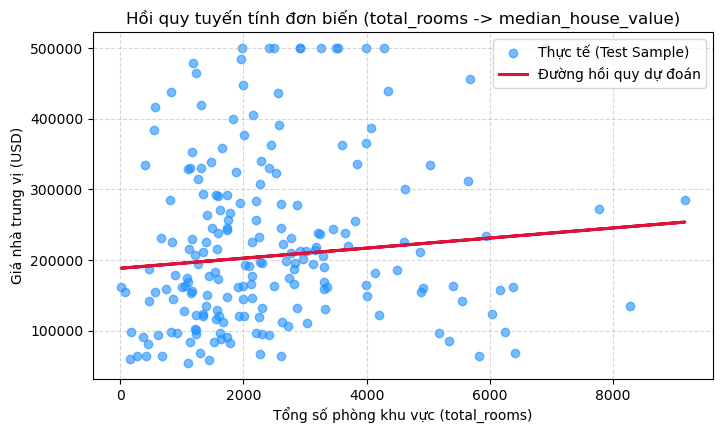

In [12]:
# Lấy mẫu 200 điểm kiểm thử để vẽ đường hồi quy trực quan
sample_indices = np.random.RandomState(42).choice(len(X_test_s), size=200, replace=False)
X_sub = X_test_s.iloc[sample_indices]
y_sub = y_test_s.iloc[sample_indices]

plt.figure(figsize=(8, 4.5))
plt.scatter(X_sub, y_sub, color='dodgerblue', alpha=0.6, label='Thực tế (Test Sample)')
plt.plot(X_sub, reg_simple.predict(X_sub), color='crimson', linewidth=2.2, label='Đường hồi quy dự đoán')
plt.xlabel("Tổng số phòng khu vực (total_rooms)")
plt.ylabel("Giá nhà trung vị (USD)")
plt.title("Hồi quy tuyến tính đơn biến (total_rooms -> median_house_value)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. THỰC HÀNH 5-2: HỒI QUY TUYẾN TÍNH ĐA BIẾN


In [13]:
# Chọn tập biến đa biến
features_multi = ["median_income", "total_rooms", "households"]
X_multi = df_housing[features_multi]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_target, test_size=0.2, random_state=42
)

# Huấn luyện mô hình hồi quy đa biến
reg_multi = LinearRegression()
reg_multi.fit(X_train_m, y_train_m)

y_pred_m = reg_multi.predict(X_test_m)
rmse_m = np.sqrt(mean_squared_error(y_test_m, y_pred_m))
r2_m = r2_score(y_test_m, y_pred_m)

# Bảng trọng số hệ số
coef_df = pd.DataFrame({
    "Thuộc tính đầu vào": features_multi,
    "Hệ số hồi quy (Slope)": reg_multi.coef_
})
print(f"Hệ số chặn (Intercept): {reg_multi.intercept_:.2f}")
coef_df

Hệ số chặn (Intercept): 16935.59


,Thuộc tính đầu vào,Hệ số hồi quy (Slope)
0,median_income,47014.256400
1,total_rooms,-24.049259
2,households,142.696905


### So sánh đối chiếu hiệu năng giữa Đơn biến và Đa biến

In [14]:
comparison_table = pd.DataFrame({
    "Mô hình": ["Hồi quy đơn biến (total_rooms)", "Hồi quy đa biến (income + rooms + households)"],
    "RMSE (USD - Càng nhỏ càng tốt)": [rmse_val, rmse_m],
    "R² Score (Càng lớn càng tốt)": [r2_val, r2_m],
    "Mức cải thiện RMSE": ["Gốc", f"-{rmse_val - rmse_m:.2f} USD"]
})
comparison_table

,Mô hình,RMSE (USD - Càng nhỏ càng tốt),R² Score (Càng lớn càng tốt),Mức cải thiện RMSE
0,Hồi quy đơn biến (total_rooms),113439.889248,0.017970,Gốc
1,Hồi quy đa biến (income + rooms + households),81975.739549,0.487181,-31464.15 USD


## 3. THỰC HÀNH 5-3: PHÂN LOẠI NHỊ PHÂN VỚI LOGISTIC REGRESSION


In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

bank_df = pd.read_csv("dataset/bank+marketing/bank/bank.csv", sep=";")

# Chọn đặc trưng biết trước cuộc gọi (loại bỏ duration để chống Data Leakage)
X_bank = bank_df[["age", "balance", "campaign"]]
y_bank = bank_df["y"]

# Phân chia phân tầng (stratify=y)
X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_bank, y_bank, test_size=0.2, stratify=y_bank, random_state=42
)

# Pipeline chuẩn hóa và hồi quy Logistic cân bằng trọng số
log_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)
log_pipe.fit(X_b_train, y_b_train)
y_b_pred = log_pipe.predict(X_b_test)

print("Tần số nhãn mục tiêu thực tế:\n", y_bank.value_counts(normalize=True).round(4))
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_b_test, y_b_pred, zero_division=0))

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/bank+marketing/bank/bank.csv'

### Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)

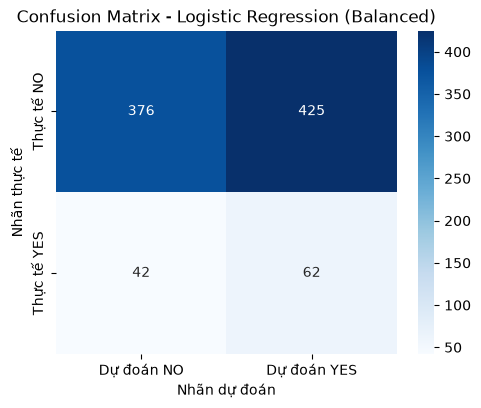

In [ ]:
cm_k = confusion_matrix(y_b_test, y_b_pred, labels=["no", "yes"])

plt.figure(figsize=(5.5, 4.2))
sns.heatmap(cm_k, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Dự đoán NO", "Dự đoán YES"],
            yticklabels=["Thực tế NO", "Thực tế YES"])
plt.title("Confusion Matrix - Logistic Regression (Balanced)")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

## 4. THỰC HÀNH 5-4: HỌC KHÔNG GIÁM SÁT VỚI K-MEANS


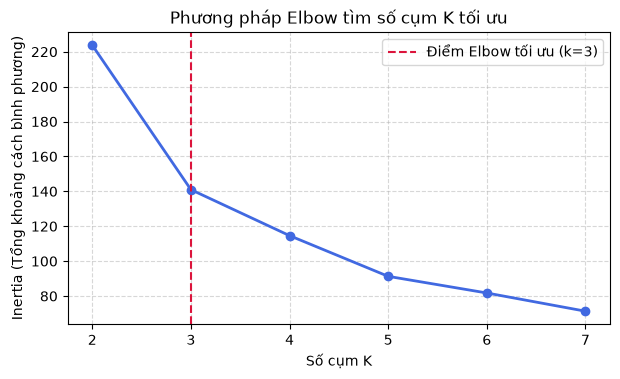

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

iris_data = pd.read_csv("dataset/iris.csv")
iris_features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X_iris = iris_data[iris_features]

# Chuẩn hóa đặc trưng
X_iris_scaled = StandardScaler().fit_transform(X_iris)

# Khảo sát Inertia theo K từ 2 đến 7
inertias_list = []
k_range = range(2, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_iris_scaled)
    inertias_list.append(km.inertia_)

# Đồ thị Elbow
plt.figure(figsize=(7, 3.8))
plt.plot(k_range, inertias_list, marker='o', color='royalblue', linewidth=2)
plt.axvline(x=3, color='crimson', linestyle='--', label='Điểm Elbow tối ưu (k=3)')
plt.xlabel("Số cụm K")
plt.ylabel("Inertia (Tổng khoảng cách bình phương)")
plt.title("Phương pháp Elbow tìm số cụm K tối ưu")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Huấn luyện K-Means với K=3 và Đối chiếu nhãn loài

Hệ số Silhouette Score (K=3): 0.4590


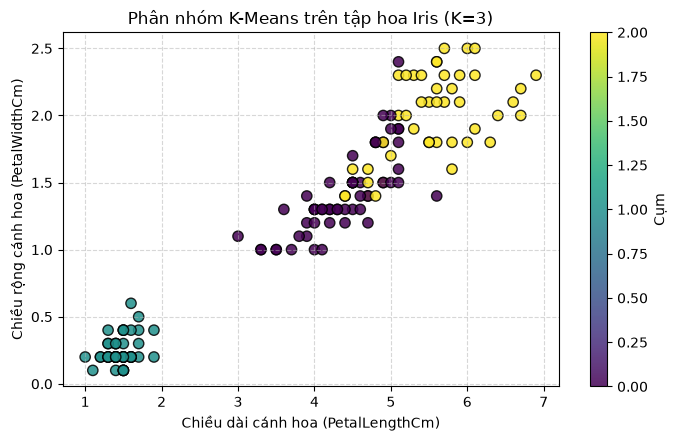

Cụm K-Means,0,1,2
Loài thực tế,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,14,0,36


In [ ]:
kmeans_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_k = kmeans_k3.fit_predict(X_iris_scaled)

print(f"Hệ số Silhouette Score (K=3): {silhouette_score(X_iris_scaled, clusters_k):.4f}")

# Vẽ đồ thị phân cụm
plt.figure(figsize=(8, 4.6))
sc = plt.scatter(X_iris["PetalLengthCm"], X_iris["PetalWidthCm"], 
                 c=clusters_k, cmap='viridis', s=55, edgecolors='k', alpha=0.85)
plt.xlabel("Chiều dài cánh hoa (PetalLengthCm)")
plt.ylabel("Chiều rộng cánh hoa (PetalWidthCm)")
plt.title("Phân nhóm K-Means trên tập hoa Iris (K=3)")
plt.colorbar(sc, label="Cụm")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Ma trận đối chiếu nhãn
pd.crosstab(iris_data["Species"], clusters_k, rownames=["Loài thực tế"], colnames=["Cụm K-Means"])

## 5. THỰC HÀNH 5-5: ĐÁNH GIÁ NÂNG CAO VỚI K-FOLD CROSS-VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score

# 1. Đo sự dao động của Train/Test Split thông thường
scores_holdout = []
for rs in [0, 10, 42, 99, 123]:
    X_tr, X_te, y_tr, y_te = train_test_split(X_multi, y_target, test_size=0.2, random_state=rs)
    m = LinearRegression().fit(X_tr, y_tr)
    scores_holdout.append(np.sqrt(mean_squared_error(y_te, m.predict(X_te))))

# 2. Đánh giá bằng 5-Fold Cross-Validation
scores_cv = cross_val_score(LinearRegression(), X_multi, y_target, cv=5, scoring="neg_mean_squared_error")
rmse_cv = np.sqrt(-scores_cv)

eval_summary = pd.DataFrame({
    "Phương pháp": ["Train/Test Split ngẫu nhiên (5 lần)", "5-Fold Cross-Validation"],
    "RMSE Min (USD)": [min(scores_holdout), min(rmse_cv)],
    "RMSE Max (USD)": [max(scores_holdout), max(rmse_cv)],
    "RMSE Trung bình (USD)": [np.mean(scores_holdout), np.mean(rmse_cv)],
    "Độ lệch chuẩn Std (USD)": [np.std(scores_holdout), np.std(rmse_cv)]
})
eval_summary

,Phương pháp,RMSE Min (USD),RMSE Max (USD),RMSE Trung bình (USD),Độ lệch chuẩn Std (USD)
0,Train/Test Split ngẫu nhiên (5 lần),79248.444741,82173.837055,81455.832757,1111.316612
1,5-Fold Cross-Validation,72586.561808,88102.953499,82505.963500,5622.395295


## 6. THỰC HÀNH 5-6 & 5-7: TỐI ƯU SIÊU THAM SỐ (GRID SEARCH VS RANDOM SEARCH)

In [ ]:
import time
from scipy.stats import randint
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

X_i = iris_data[iris_features]
y_i = iris_data["Species"]
X_i_tr, X_i_te, y_i_tr, y_i_te = train_test_split(X_i, y_i, test_size=0.2, stratify=y_i, random_state=42)

# Grid Search (40 tổ hợp)
grid_space = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': [2, 4, 6, 8],
    'criterion': ['gini', 'entropy']
}
t0 = time.time()
gs_model = GridSearchCV(DecisionTreeClassifier(random_state=42), grid_space, cv=5, scoring='accuracy')
gs_model.fit(X_i_tr, y_i_tr)
time_gs = time.time() - t0

# Random Search (10 tổ hợp ngẫu nhiên)
rand_space = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': randint(2, 10),
    'criterion': ['gini', 'entropy']
}
t0 = time.time()
rs_model = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), rand_space, n_iter=10, cv=5, scoring='accuracy', random_state=42)
rs_model.fit(X_i_tr, y_i_tr)
time_rs = time.time() - t0

search_comparison = pd.DataFrame({
    "Thuật toán tìm kiếm": ["Grid Search (40 tổ hợp)", "Random Search (10 tổ hợp)"],
    "Thời gian (giây)": [time_gs, time_rs],
    "Best CV Accuracy": [gs_model.best_score_, rs_model.best_score_],
    "Test Accuracy": [gs_model.best_estimator_.score(X_i_te, y_i_te), rs_model.best_estimator_.score(X_i_te, y_i_te)],
    "Bộ tham số tối ưu": [str(gs_model.best_params_), str(rs_model.best_params_)]
})
search_comparison

,Thuật toán tìm kiếm,Thời gian (giây),Best CV Accuracy,Test Accuracy,Bộ tham số tối ưu
0,Grid Search (40 tổ hợp),0.748935,0.941667,0.933333,"{'criterion': 'gini', 'max_depth': 4, 'min_sam..."
1,Random Search (10 tổ hợp),0.190891,0.933333,0.966667,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."


### Sơ đồ Cây quyết định tối ưu

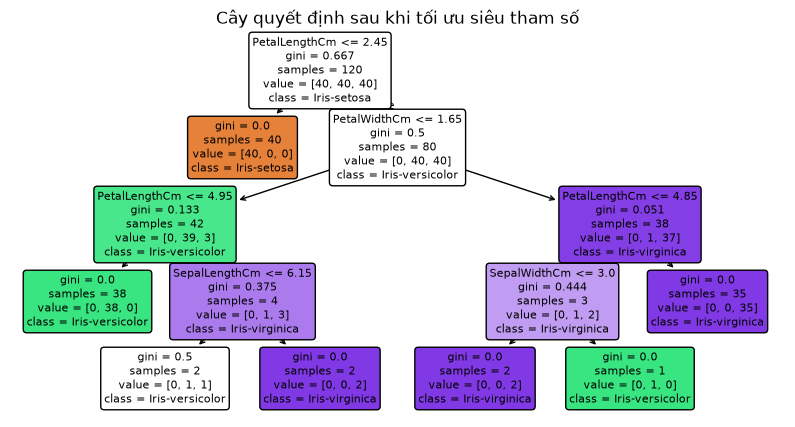

In [ ]:
plt.figure(figsize=(10, 5))
plot_tree(gs_model.best_estimator_, filled=True, feature_names=iris_features, class_names=sorted(y_i.unique()), rounded=True)
plt.title("Cây quyết định sau khi tối ưu siêu tham số")
plt.show()

## 7. THỰC HÀNH 5-8: CHUẨN HÓA QUY TRÌNH VỚI PIPELINE & COLUMNTRANSFORMER

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_cols = ["age", "balance", "campaign", "pdays", "previous"]
categorical_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

X_all = bank_df[numeric_cols + categorical_cols]
y_all = bank_df["y"]

X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

# Xây dựng Pipeline riêng cho từng nhóm thuộc tính
num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor_k = ColumnTransformer([
    ('num', num_pipe, numeric_cols),
    ('cat', cat_pipe, categorical_cols)
])

pipeline_khanh = Pipeline([
    ('preprocessor', preprocessor_k),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

pipeline_khanh.fit(X_tr_f, y_tr_f)
print(f"Accuracy trên tập test: {pipeline_khanh.score(X_te_f, y_te_f):.4f}")

# Dự đoán mẫu khách hàng mới
sample_cus = pd.DataFrame({
    "age": [35], "balance": [1200], "campaign": [1], "pdays": [-1], "previous": [0],
    "job": ["technician"], "marital": ["married"], "education": ["secondary"],
    "default": ["no"], "housing": ["yes"], "loan": ["no"], "contact": ["cellular"],
    "month": ["may"], "poutcome": ["unknown"]
})

pred_res = pipeline_khanh.predict(sample_cus)[0]
pred_proba = pipeline_khanh.predict_proba(sample_cus)[0]
print(f"Dự đoán đăng ký: {pred_res} (Xác suất YES: {pred_proba[1]*100:.2f}%)")

Accuracy trên tập test: 0.8873
Dự đoán đăng ký: no (Xác suất YES: 7.24%)


## 8. BÀI TẬP MỞ RỘNG: KỸ NGHỆ ĐẶC TRƯNG & HỒI QUY RIDGE/LASSO
Tạo thêm 2 biến kinh tế: `BedroomShare` và `RoomsPerHousehold`.

In [ ]:
from sklearn.linear_model import Ridge, Lasso

df_ext = df_housing.copy()
df_ext["BedroomShare"] = (df_ext["total_bedrooms"] / df_ext["total_rooms"]).fillna(0.2)
df_ext["RoomsPerHousehold"] = df_ext["total_rooms"] / df_ext["households"]

fe_cols = ["median_income", "total_rooms", "households", "BedroomShare", "RoomsPerHousehold"]
X_ext = df_ext[fe_cols]
y_ext = df_ext["median_house_value"]

X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(X_ext, y_ext, test_size=0.2, random_state=42)

model_ext = LinearRegression().fit(X_tr_e, y_tr_e)
sc_e = StandardScaler()
X_tr_sc = sc_e.fit_transform(X_tr_e)
X_te_sc = sc_e.transform(X_te_e)

ridge_clf = Ridge(alpha=100.0).fit(X_tr_sc, y_tr_e)
lasso_clf = Lasso(alpha=100.0).fit(X_tr_sc, y_tr_e)

pd.DataFrame({
    "Đặc trưng": fe_cols,
    "Hệ số Linear": model_ext.coef_,
    "Hệ số Ridge (alpha=100)": ridge_clf.coef_,
    "Hệ số Lasso (alpha=100)": lasso_clf.coef_
})

,Đặc trưng,Hệ số Linear,Hệ số Ridge (alpha=100),Hệ số Lasso (alpha=100)
0,median_income,52513.454783,98751.102866,99664.571582
1,total_rooms,-11.505870,-21532.367191,-22453.886197
2,households,72.422839,24226.815860,25082.798461
3,BedroomShare,451520.881704,25939.568191,26313.253051
4,RoomsPerHousehold,760.277873,1364.736685,1325.189969
